# Reconstruction accuracy and binary encoding performance

Evaluate bVAE, ESM2 650M-bVAE, and ESM2 650M-bVAE (HPO) on MHC-I binding peptides. The analysis compares reconstructed sequences with test sequences and relates sequence distances to Hamming distances in the binary latent space.

In [1]:
# Evaluate sequence reconstruction accuracy and binary encoding performance for MHC-I binding peptides.
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import warnings
warnings.filterwarnings("ignore")

import matplotlib as mpl
mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['axes.unicode_minus'] = False

## Load test sequences and model outputs

In [3]:
# Load test sequences and reconstructed sequences.
plm_res = "...\\pLM-bVAE\\reproduction_paper\\outputs\\"
plm_data = "...\\pLM-bVAE\\reproduction_paper\\data\\"
test_seqs = pd.read_csv(plm_data + "peptide\\bvae\\test.txt", sep="\t", header=None, names=["seqs"])
test_seqs["seqs"] = test_seqs["seqs"].str.replace(" ", "")
# bvae
dec_bvae = pd.read_csv(plm_res + "peptide_models\\bvae\\model_output\\binary\\decoded.txt", sep="\t", header=None, names=["seqs"])
dec_bvae["seqs"] = dec_bvae["seqs"].str.replace(" ", "")
# esm_650m
dec_esm_650m = pd.read_csv(plm_res + "peptide_models\\esm_650m\\model_output\\binary\\decoded.txt", sep="\t", header=None, names=["seqs"])
dec_esm_650m["seqs"] = dec_esm_650m["seqs"].str.replace(" ", "")
# esm_650m_opt
dec_esm_650m_opt = pd.read_csv(plm_res + "peptide_models\\esm_650m_opt\\model_output\\binary\\decoded.txt", sep="\t", header=None, names=["seqs"])
dec_esm_650m_opt["seqs"] = dec_esm_650m_opt["seqs"].str.replace(" ", "")

## Levenshtein reconstruction accuracy

In [4]:
# Calculate Levenshtein distances between test and decoded sequences.
import Levenshtein
def cal_levenshtein_dist(test_seqs, decoded_seqs):
    lev_distances = []
    for original, decoded in zip(test_seqs["seqs"], decoded_seqs["seqs"]):
        dist = Levenshtein.distance(original, decoded)
        lev_distances.append(dist)
    return lev_distances

In [5]:
# bvae
dist_bvae = cal_levenshtein_dist(test_seqs, dec_bvae)
# esm_650m
dist_esm_650m = cal_levenshtein_dist(test_seqs, dec_esm_650m)
# esm_650m_opt
dist_esm_650m_opt = cal_levenshtein_dist(test_seqs, dec_esm_650m_opt)

In [6]:
df_Levdist = pd.DataFrame({
    "distance": np.r_[dist_bvae, dist_esm_650m, dist_esm_650m_opt],
    "series": (["bvae"] * len(dist_bvae)) + (["esm_650m"] * len(dist_esm_650m)) + (["esm_650m_opt"] * len(dist_esm_650m_opt))
})

In [7]:
# Calculate the fraction of exact reconstructions for each series.
df_Levdist_zero = df_Levdist[df_Levdist["distance"] == 0].groupby("series").size() / df_Levdist.groupby("series").size()
df_Levdist_zero

series
bvae            0.024671
esm_650m        0.126645
esm_650m_opt    0.974507
dtype: float64

In [8]:
df_Levdist

,distance,series
0,3,bvae
1,2,bvae
2,6,bvae
3,8,bvae
4,5,bvae
...,...,...
3643,0,esm_650m_opt
3644,0,esm_650m_opt
3645,0,esm_650m_opt
3646,0,esm_650m_opt


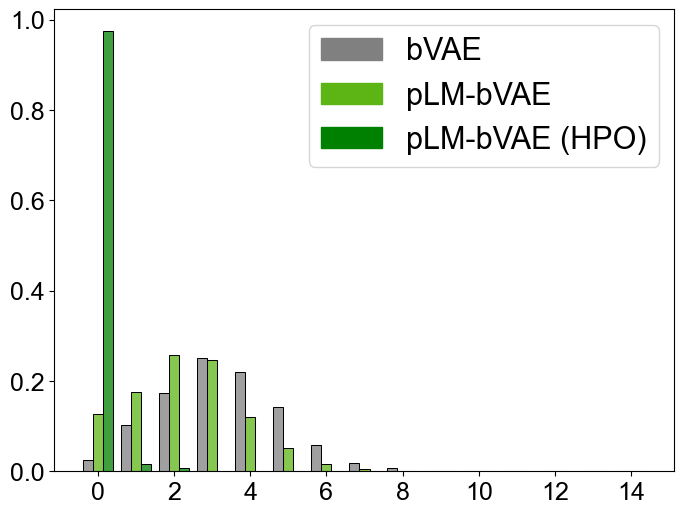

In [9]:
plt.figure(figsize=(8, 6))
mind = min(np.min(dist_bvae), np.min(dist_esm_650m), np.min(dist_esm_650m_opt))
maxd = max(np.max(dist_bvae), np.max(dist_esm_650m), np.max(dist_esm_650m_opt))
bins = np.arange(mind, maxd + 2) - 0.5  # Use unit-width bins centered on integers.

# Plot the density histogram for each series.
sns.histplot(
    data=df_Levdist, x="distance", hue="series", stat="probability", common_norm=False,
    bins=bins, multiple="dodge", shrink=0.8, discrete=True,
    palette={"bvae": "gray", "esm_650m": "#5CB514", "esm_650m_opt": "green"},
    legend=False,
)

plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
# Specify the legend colors and labels.
handles = [
    Patch(facecolor='gray', edgecolor='gray', label='bVAE'),
    Patch(facecolor='#5CB514', edgecolor='#5CB514', label='pLM-bVAE'),
    Patch(facecolor='green', edgecolor='green', label='pLM-bVAE (HPO)')
]
plt.legend(handles=handles, fontsize=22, title_fontsize=12, loc='upper right')

plt.xlabel('')
plt.ylabel('')
plt.show()

## BLOSUM62 reconstruction accuracy

In [10]:
# Calculate BLOSUM62 scores.
from Bio.Align import PairwiseAligner, substitution_matrices

def cal_blosum62_score(test_seqs, decoded_seqs):
    aligner = PairwiseAligner(mode="global")
    aligner.substitution_matrix = substitution_matrices.load("BLOSUM62")
    aligner.open_gap_score = -10
    aligner.extend_gap_score = -0.5

    scores = []
    for original, decoded in zip(test_seqs["seqs"], decoded_seqs["seqs"]):
        # Calculate the score without constructing the alignment.
        score = aligner.score(original, decoded)
        scores.append(score)
    return scores

In [11]:
# Calculate BLOSUM62 scores.
# bvae
b62_bvae = cal_blosum62_score(test_seqs, dec_bvae)
# esm_650m
b62_esm_650m = cal_blosum62_score(test_seqs, dec_esm_650m)
# esm_650m_opt
b62_esm_650m_opt = cal_blosum62_score(test_seqs, dec_esm_650m_opt)

In [12]:
df_bs62 = pd.DataFrame({
    "score": np.r_[b62_bvae, b62_esm_650m, b62_esm_650m_opt],
    "series": (["bvae"] * len(b62_bvae)) + (["esm_650m"] * len(b62_esm_650m)) + (["esm_650m_opt"] * len(b62_esm_650m_opt))
})

In [13]:
df_bs62["score"].sort_values()

941    -14.5
1066   -14.0
153     -7.0
366     -6.5
78      -6.0
        ... 
2543    61.0
3423    62.0
3063    64.0
3263    67.0
3578    68.0
Name: score, Length: 3648, dtype: float64

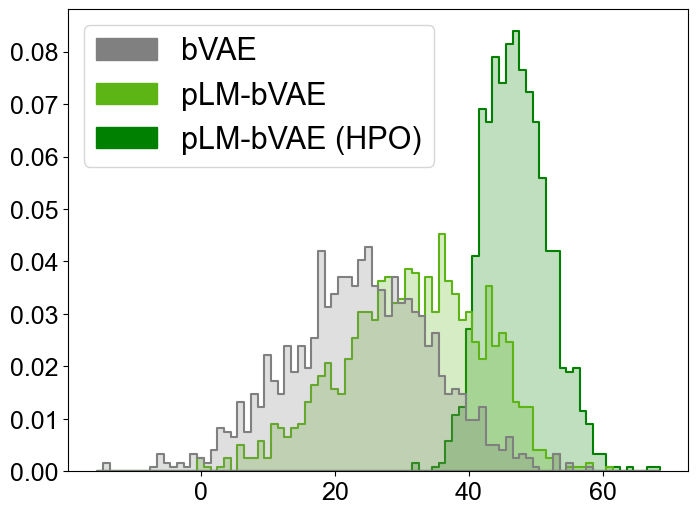

In [14]:
plt.figure(figsize=(8, 6))

min_score = int(np.floor(df_bs62["score"].min()))
max_score = int(np.ceil(df_bs62["score"].max()))
bins = np.arange(min_score, max_score + 2) - 0.5

sns.histplot(
    data=df_bs62, x="score", hue="series", stat="probability", common_norm=False,
    bins=bins, element='step', linewidth=1.5,
    palette={"bvae": "gray", "esm_650m": "#5CB514", "esm_650m_opt": "green"},
    legend=False,
)

plt.xticks(fontsize=18)
plt.yticks(fontsize=18)

# Specify the legend colors and labels.
handles = [
    Patch(facecolor='gray', edgecolor='gray', label='bVAE'),
    Patch(facecolor='#5CB514', edgecolor='#5CB514', label='pLM-bVAE'),
    Patch(facecolor='green', edgecolor='green', label='pLM-bVAE (HPO)')
]
plt.legend(handles=handles, fontsize=22, loc='upper left')

plt.xlabel('')
plt.ylabel('')
plt.show()

In [15]:
# Calculate the 95th percentile of bVAE BLOSUM62 scores.
bvae_top5 = np.percentile(df_bs62[df_bs62["series"] == "bvae"]["score"], 95)
bvae_top5

np.float64(41.0)

In [16]:
def top_tail_global_threshold(
    df,
    score_col="score",
    series_col="series",
):
    rows = []

    # Calculate the upper 5% threshold for bVAE scores.
    threshold = bvae_top5

    for series, sub in df.groupby(series_col):
        scores = sub[score_col].dropna()
        n_total = len(scores)

        n_top = (scores >= threshold).sum()
        frac_top = n_top / n_total

        rows.append({
            "top_percent": 5,
            "global_threshold": threshold,
            series_col: series,
            "n_total": n_total,
            "n_top": n_top,
            "fraction_top": frac_top,
        })

    return pd.DataFrame(rows)

In [17]:
global_top_tail_df = top_tail_global_threshold(
    df_bs62,
    score_col="score",
    series_col="series"
)

global_top_tail_df

,top_percent,global_threshold,series,n_total,n_top,fraction_top
0,5,41.0,bvae,1216,70,0.057566
1,5,41.0,esm_650m,1216,259,0.212993
2,5,41.0,esm_650m_opt,1216,1142,0.939145


## Sequence distances and binary encoding

In [18]:
# Define a function to calculate pairwise Levenshtein distances among test sequences.
import Levenshtein
from tqdm import tqdm
def calculate_levenshtein_distance_matrix(seqs):
    n = seqs.shape[0]
    dist_matrix_Lev = np.zeros([n, n])
    for i in tqdm(range(n)):
        for j in range(i + 1, n):
            dist = Levenshtein.distance(seqs.iloc[i]['seqs'], seqs.iloc[j]['seqs'])
            dist_matrix_Lev[i][j] = dist
            dist_matrix_Lev[j][i] = dist
    return dist_matrix_Lev

In [19]:
# Calculate the Levenshtein distance matrix.
lev_dist_mat_test_seqs = calculate_levenshtein_distance_matrix(test_seqs)

  0%|          | 0/1216 [00:00<?, ?it/s]

  0%|          | 3/1216 [00:00<01:03, 19.18it/s]

  0%|          | 5/1216 [00:00<01:19, 15.18it/s]

  1%|          | 7/1216 [00:00<01:16, 15.80it/s]

  1%|          | 9/1216 [00:00<01:11, 16.90it/s]

...

 92%|█████████▏| 1118/1216 [00:36<00:00, 116.45it/s]

 93%|█████████▎| 1135/1216 [00:36<00:00, 131.98it/s]

 95%|█████████▍| 1155/1216 [00:37<00:00, 151.67it/s]

 98%|█████████▊| 1189/1216 [00:37<00:00, 206.06it/s]

100%|██████████| 1216/1216 [00:37<00:00, 32.70it/s] 

In [20]:
# bvae
binary_bvae = pd.read_csv(plm_res + "peptide_models\\bvae\\model_output\\binary\\vectors.txt", sep="\t", header=None, names=["seqs"])
binary_bvae["seqs"] = binary_bvae["seqs"].str.replace(" ", "")

# esm_650m
binary_esm_650m = pd.read_csv(plm_res + "peptide_models\\esm_650m\\model_output\\binary\\vectors.txt", sep="\t", header=None, names=["seqs"])
binary_esm_650m["seqs"] = binary_esm_650m["seqs"].str.replace(" ", "")

# esm_650m_opt
binary_esm_650m_opt = pd.read_csv(plm_res + "peptide_models\\esm_650m_opt\\model_output\\binary\\vectors.txt", sep="\t", header=None, names=["seqs"])
binary_esm_650m_opt["seqs"] = binary_esm_650m_opt["seqs"].str.replace(" ", "")

In [21]:
# Define a function to calculate pairwise Hamming distances.
from Levenshtein import hamming
from tqdm import tqdm
def calculate_hamming_distance_matrix(vecs):
    n = vecs.shape[0]
    dist_matrix_ham = np.zeros([n, n])
    for i in tqdm(range(n)):
        for j in range(i + 1, n):
            dist = hamming(vecs.iloc[i]['seqs'], vecs.iloc[j]['seqs'])
            dist_matrix_ham[i][j] = dist
            dist_matrix_ham[j][i] = dist
    return dist_matrix_ham

In [22]:
# Calculate the Hamming distance matrix.
ham_dist_mat_test_seqs_bvae = calculate_hamming_distance_matrix(binary_bvae)
ham_dist_mat_test_seqs_esm_650m = calculate_hamming_distance_matrix(binary_esm_650m)
ham_dist_mat_test_seqs_esm_650m_opt = calculate_hamming_distance_matrix(binary_esm_650m_opt)

  0%|          | 0/1216 [00:00<?, ?it/s]

  0%|          | 2/1216 [00:00<01:38, 12.37it/s]

  0%|          | 4/1216 [00:00<01:39, 12.24it/s]

  0%|          | 6/1216 [00:00<01:38, 12.29it/s]

  1%|          | 8/1216 [00:00<01:40, 12.00it/s]

...

 92%|█████████▏| 1116/1216 [00:21<00:00, 118.15it/s]

 93%|█████████▎| 1130/1216 [00:21<00:00, 119.32it/s]

 94%|█████████▍| 1147/1216 [00:21<00:00, 131.13it/s]

 96%|█████████▋| 1171/1216 [00:22<00:00, 158.57it/s]

100%|██████████| 1216/1216 [00:22<00:00, 55.07it/s] 

In [23]:
# Flatten the upper triangle of the matrix.
lev_dist_mat_test_seqs_triu = lev_dist_mat_test_seqs[np.triu_indices_from(lev_dist_mat_test_seqs, k=1)]
ham_dist_mat_test_seqs_bvae_triu = ham_dist_mat_test_seqs_bvae[np.triu_indices_from(ham_dist_mat_test_seqs_bvae, k=1)]
ham_dist_mat_test_seqs_esm_650m_triu = ham_dist_mat_test_seqs_esm_650m[np.triu_indices_from(ham_dist_mat_test_seqs_esm_650m, k=1)]
ham_dist_mat_test_seqs_esm_650m_opt_triu = ham_dist_mat_test_seqs_esm_650m_opt[np.triu_indices_from(ham_dist_mat_test_seqs_esm_650m_opt, k=1)]

# Prepare Levenshtein distances as categories and Hamming distances as numerical values.
df_bvae = pd.DataFrame({
    "Levenshtein": lev_dist_mat_test_seqs_triu,
    "Hamming": ham_dist_mat_test_seqs_bvae_triu
})
df_esm = pd.DataFrame({
    "Levenshtein": lev_dist_mat_test_seqs_triu,
    "Hamming": ham_dist_mat_test_seqs_esm_650m_triu
})
df_esm_opt = pd.DataFrame({
    "Levenshtein": lev_dist_mat_test_seqs_triu,
    "Hamming": ham_dist_mat_test_seqs_esm_650m_opt_triu
})

# Convert Levenshtein distances to integers.
df_bvae["Levenshtein"] = df_bvae["Levenshtein"].astype(int)
df_esm["Levenshtein"] = df_esm["Levenshtein"].astype(int)
df_esm_opt["Levenshtein"] = df_esm_opt["Levenshtein"].astype(int)

In [24]:
# Calculate the Spearman correlation.
s1 = df_bvae.corr(method="spearman").iloc[0, 1]
s2 = df_esm.corr(method="spearman").iloc[0, 1]
s3 = df_esm_opt.corr(method="spearman").iloc[0, 1]

print("bvae Spearman correlation:", s1)
print("esm_650m Spearman correlation:", s2)
print("esm_650m_opt Spearman correlation:", s3)

bvae Spearman correlation: 0.3002157977732518
esm_650m Spearman correlation: 0.4050721308920113
esm_650m_opt Spearman correlation: 0.5033600856668741


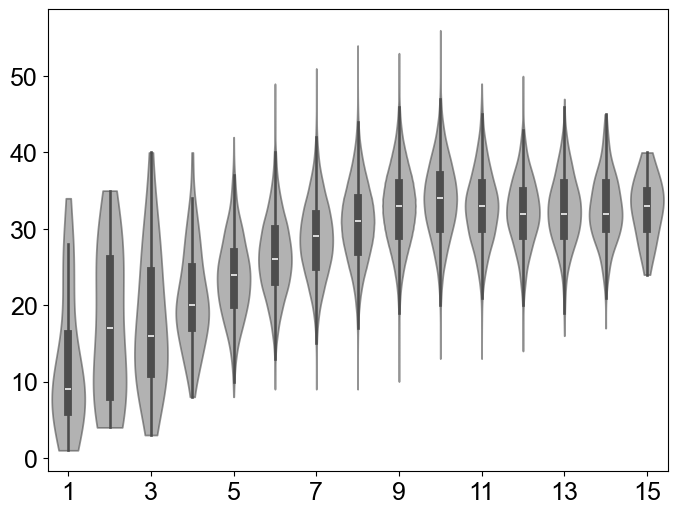

In [25]:
from matplotlib.ticker import MaxNLocator

plt.figure(figsize=(8, 6))
ax1 = sns.violinplot(x="Levenshtein", y="Hamming", data=df_bvae, cut=0, scale="width", bw_adjust=1.3,# Adjust the plot.
                     inner="box", color="gray")
# plt.ylim(-5, 60)

# plt.title('Levenshtein vs Hamming')
# Adjust transparency.
for violin in ax1.collections:
    violin.set_alpha(0.6)

# Use integer ticks on the horizontal axis.
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

# Remove axis labels.
ax1.set_xlabel("")
ax1.set_ylabel("")

plt.xticks(fontsize=18)
plt.yticks(fontsize=18)

plt.show()

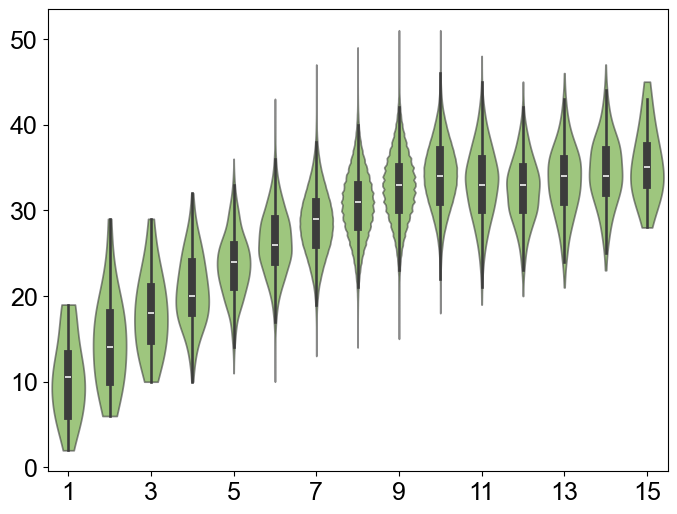

In [26]:
plt.figure(figsize=(8, 6))
ax1 = sns.violinplot(x="Levenshtein", y="Hamming", data=df_esm, cut=0, scale="width", bw_adjust=1.3,# Adjust the plot.
                     inner="box", color="#5CB514")
# plt.ylim(-5, 60)

# plt.title('Levenshtein vs Hamming')
# Adjust transparency.
for violin in ax1.collections:
    violin.set_alpha(0.6)

# Use integer ticks on the horizontal axis.
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

# Remove axis labels.
ax1.set_xlabel("")
ax1.set_ylabel("")

plt.xticks(fontsize=18)
plt.yticks(fontsize=18)

plt.show()

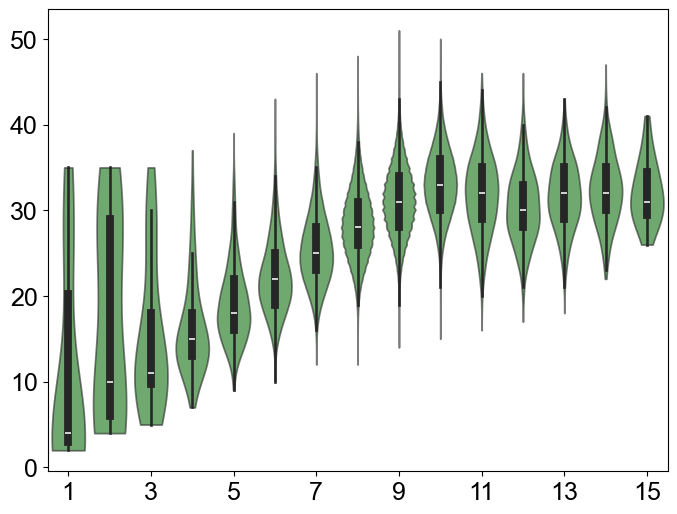

In [27]:
plt.figure(figsize=(8, 6))
ax1 = sns.violinplot(x="Levenshtein", y="Hamming", data=df_esm_opt, cut=0, scale="width", bw_adjust=1.3,# Adjust the plot.
                     inner="box", color="green")
# plt.ylim(-5, 60)

# plt.title('Levenshtein vs Hamming')
# Adjust transparency.
for violin in ax1.collections:
    violin.set_alpha(0.6)

# Use integer ticks on the horizontal axis.
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

# Remove axis labels.
ax1.set_xlabel("")
ax1.set_ylabel("")

plt.xticks(fontsize=18)
plt.yticks(fontsize=18)

plt.show()

## BLOSUM62 similarity and binary encoding

In [28]:
# Calculate the BLOSUM62 score matrix.
import numpy as np
from Bio.Align import PairwiseAligner, substitution_matrices
from tqdm import tqdm
from scipy.stats import pearsonr, spearmanr

# Calculate pairwise BLOSUM62 global alignment scores.
def calculate_blosum62_alignment_matrix(vecs):
    n = vecs.shape[0]
    mat = np.zeros([n, n])

    aligner = PairwiseAligner(mode="global")
    aligner.substitution_matrix = substitution_matrices.load("BLOSUM62")
    aligner.open_gap_score = -10
    aligner.extend_gap_score = -0.5

    for i in tqdm(range(n)):
        for j in range(i + 1, n):
            score = aligner.score(vecs.iloc[i]['seqs'], vecs.iloc[j]['seqs'])
            mat[i][j] = score
            mat[j][i] = score
    return mat

# Use the same correlation function.
def distance_matrix_correlation(mat1, mat2, method="pearson"):
    vec1 = mat1[np.triu_indices_from(mat1, k=1)]
    vec2 = mat2[np.triu_indices_from(mat2, k=1)]
    
    if method == "pearson":
        r, _ = pearsonr(vec1, vec2)
    elif method == "spearman":
        r, _ = spearmanr(vec1, vec2)
    else:
        raise ValueError("method must be 'pearson' or 'spearman'")
    return r

In [29]:
# Calculate the BLOSUM62 score matrix.
blosum62_matrix_test_seqs = calculate_blosum62_alignment_matrix(test_seqs)

  0%|          | 0/1216 [00:00<?, ?it/s]

  0%|          | 2/1216 [00:00<01:36, 12.57it/s]

  0%|          | 4/1216 [00:00<01:24, 14.37it/s]

  0%|          | 6/1216 [00:00<01:21, 14.91it/s]

  1%|          | 8/1216 [00:00<01:25, 14.15it/s]

...

 91%|█████████ | 1104/1216 [00:40<00:00, 126.51it/s]

 92%|█████████▏| 1122/1216 [00:40<00:00, 140.82it/s]

 94%|█████████▍| 1143/1216 [00:40<00:00, 160.04it/s]

 97%|█████████▋| 1176/1216 [00:40<00:00, 202.42it/s]

100%|██████████| 1216/1216 [00:40<00:00, 29.95it/s] 

In [30]:
# Calculate the Spearman correlation.
s1 = distance_matrix_correlation(blosum62_matrix_test_seqs,
                                 ham_dist_mat_test_seqs_bvae,
                                 method="spearman")

s2 = distance_matrix_correlation(blosum62_matrix_test_seqs,
                                 ham_dist_mat_test_seqs_esm_650m,
                                 method="spearman")

s3 = distance_matrix_correlation(blosum62_matrix_test_seqs,
                                 ham_dist_mat_test_seqs_esm_650m_opt,
                                 method="spearman")

print("bvae Spearman correlation:", s1)
print("esm_650m Spearman correlation:", s2)
print("esm_650m_opt Spearman correlation:", s3)

bvae Spearman correlation: -0.2458691247311224
esm_650m Spearman correlation: -0.3787933925082732
esm_650m_opt Spearman correlation: -0.5862027942182595


In [31]:
blosum62_matrix_test_seqs_triu = blosum62_matrix_test_seqs[np.triu_indices_from(blosum62_matrix_test_seqs, k=1)]
ham_dist_mat_test_seqs_bvae_triu = ham_dist_mat_test_seqs_bvae[np.triu_indices_from(ham_dist_mat_test_seqs_bvae, k=1)]
ham_dist_mat_test_seqs_esm_650m_triu = ham_dist_mat_test_seqs_esm_650m[np.triu_indices_from(ham_dist_mat_test_seqs_esm_650m, k=1)]
ham_dist_mat_test_seqs_esm_650m_opt_triu = ham_dist_mat_test_seqs_esm_650m_opt[np.triu_indices_from(ham_dist_mat_test_seqs_esm_650m_opt, k=1)]

(-5.0, 60.0)

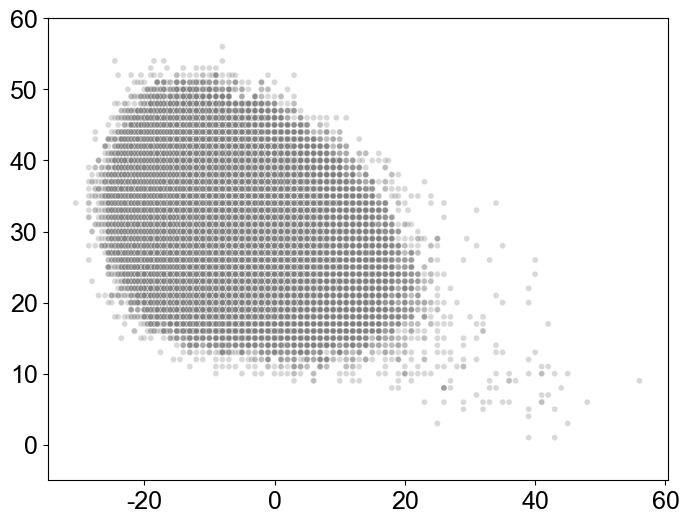

In [32]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=blosum62_matrix_test_seqs_triu, y=ham_dist_mat_test_seqs_bvae_triu, alpha=0.3, size=3, color='gray',legend=False)

plt.xticks(fontsize=18)
plt.yticks(fontsize=18)

plt.ylim(-5, 60)
# plt.title('BLOSUM62 vs Hamming')

(-5.0, 60.0)

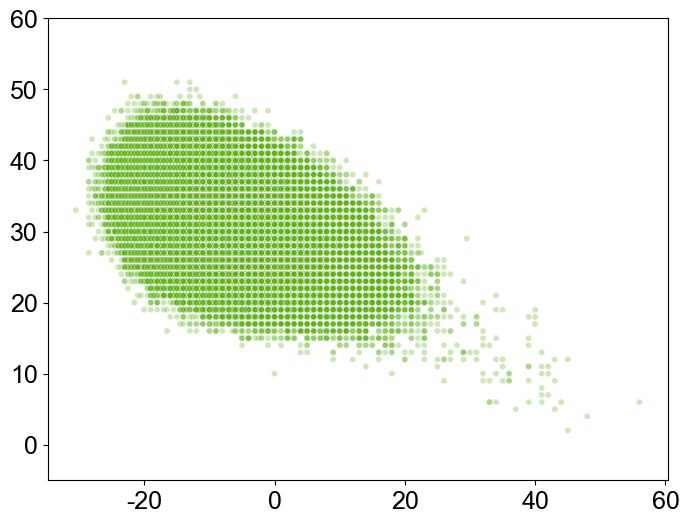

In [33]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=blosum62_matrix_test_seqs_triu, y=ham_dist_mat_test_seqs_esm_650m_triu, alpha=0.3, size=3, color='#5CB514', legend=False)

plt.xticks(fontsize=18)
plt.yticks(fontsize=18)

plt.ylim(-5, 60)
# plt.title('BLOSUM62 vs Hamming')

(-5.0, 60.0)

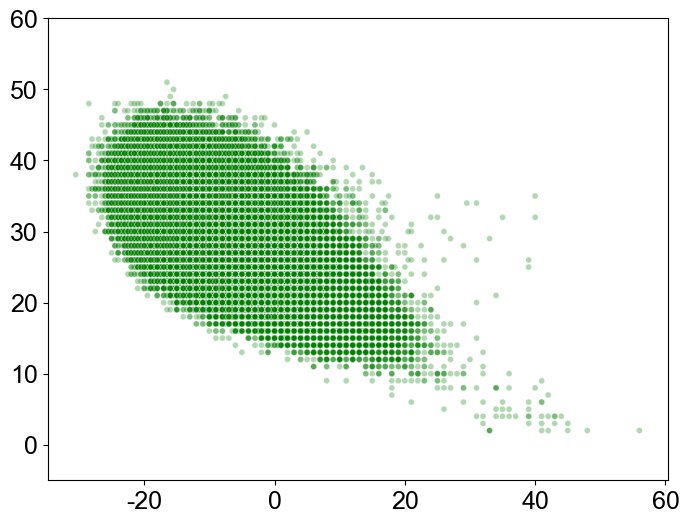

In [34]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=blosum62_matrix_test_seqs_triu, y=ham_dist_mat_test_seqs_esm_650m_opt_triu, alpha=0.3, size=3, color='green', legend=False)

plt.xticks(fontsize=18)
plt.yticks(fontsize=18)

plt.ylim(-5, 60)
# plt.title('BLOSUM62 vs Hamming')